<a href="https://colab.research.google.com/github/Z4nata/CalculoNumerico/blob/main/Atividade_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integração Numérica — Cálculo Numérico

## Aula detalhada: aproximação de integrais definidas

**Objetivos de aprendizagem**


1. interpretar a integral definida como área acumulada;
2. aproximar integrais pelas regras do ponto médio, dos trapézios e de Simpson;
3. implementar essas regras em Python;
4. comparar aproximações com um valor de referência e interpretar erros;
5. usar refinamento de malha para avaliar a convergência.



**Aluno:** Felipe Pinto Zanata — UNIFESP · Profa. Raquel Lobosco

> **Versão respondida pelo grupo.** A atividade guiada da seção 11 está resolvida no fim do notebook, item por item, e cada item termina com a **Resposta do grupo**. As células **Complemento do grupo** são extras: comparam os erros medidos com as fórmulas de erro das regras e mostram por que Simpson é tão mais eficiente que os trapézios.
>
> Para rodar no Colab: *Ambiente de execução → Executar tudo*. Nada é aleatório, então os números saem iguais a cada execução.

### 1. Integral definida e interpretação geométrica

A integral definida

$$
I=\int_a^b f(x)\,dx
$$

permite calcular a **acumulação dos valores de uma função** entre os limites $a$ e $b$. Em muitas situações, essa acumulação pode ser interpretada como uma área.

Por exemplo, se $f(x)$ representa a velocidade de um objeto ao longo do tempo, a integral da velocidade em um intervalo de tempo fornece o deslocamento do objeto nesse período. Se $f(x)$ representa a vazão de um fluido, sua integral ao longo do tempo fornece o volume acumulado.

#### Interpretação como área

Quando o gráfico de $f(x)$ está acima do eixo horizontal, isto é, quando $f(x)\geq 0$, a integral corresponde à área entre o gráfico e o eixo $x$.

Quando o gráfico está abaixo do eixo $x$, a função assume valores negativos. Nesse caso, essa região contribui negativamente para a integral. Por isso, dizemos que a integral definida representa uma **área com sinal** ou uma **acumulação líquida**: as contribuições positivas e negativas são somadas levando em conta seus sinais.

> A integral definida não é necessariamente igual à área geométrica total. Se a função assume valores positivos e negativos, as regiões abaixo do eixo $x$ são subtraídas das regiões acima dele.

#### Divisão do intervalo

Em geral, não calculamos diretamente a área sob uma curva complexa. Em vez disso, dividimos o intervalo $[a,b]$ em partes menores e aproximamos a curva por formas geométricas mais simples.

Dividimos o intervalo em $n$ subintervalos de mesma largura. O comprimento de cada subintervalo, chamado de passo ou espaçamento, é

$$
h=\frac{b-a}{n}.
$$

Os pontos que delimitam os subintervalos são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

Assim, o intervalo $[a,b]$ fica dividido nos trechos

$$
[x_0,x_1],\ [x_1,x_2],\ \ldots,\ [x_{n-1},x_n].
$$

Por exemplo, se dividirmos $[0,1]$ em quatro subintervalos, teremos

$$
n=4,\qquad h=\frac{1-0}{4}=0{,}25,
$$

e os pontos serão

$$
x_0=0,\quad x_1=0{,}25,\quad x_2=0{,}50,\quad
x_3=0{,}75,\quad x_4=1.
$$

#### Aproximação numérica da integral

Em cada subintervalo, podemos aproximar a região sob a curva por uma figura simples:

- **retângulos**, usando valores da função em pontos escolhidos;
- **trapézios**, ligando pontos consecutivos do gráfico por segmentos de reta;
- **parábolas**, ajustadas a grupos de pontos, como na regra de Simpson.

A integral é então aproximada pela soma das áreas dessas figuras. Quanto menores forem os subintervalos, mais detalhada será a representação da curva e, em geral, melhor será a aproximação.

Entretanto, aumentar o número de subintervalos também exige mais avaliações da função e mais cálculos. Além disso, uma malha mais fina não elimina automaticamente dificuldades como descontinuidades, oscilações ou ruído em dados experimentais. Por isso, a escolha do método e do número de subintervalos deve levar em conta as características do problema.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11


## 2. Regra do ponto médio

A regra do ponto médio aproxima a área sob a curva usando retângulos. Em cada subintervalo, a altura do retângulo é determinada pelo valor da função no ponto central desse intervalo.

### Construção da aproximação

Dividimos o intervalo $[a,b]$ em $n$ subintervalos de mesma largura:

$$
h=\frac{b-a}{n}.
$$

Os pontos que delimitam esses subintervalos são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

No subintervalo $[x_i,x_{i+1}]$, o ponto médio é

$$
m_i=\frac{x_i+x_{i+1}}{2}
    =a+\left(i+\frac{1}{2}\right)h.
$$

A altura do retângulo nesse subintervalo é $f(m_i)$, e sua base tem comprimento $h$. Portanto, a área aproximada desse retângulo é

$$
A_i\approx h\,f(m_i).
$$

Somando as áreas dos $n$ retângulos, obtemos a regra composta do ponto médio:

$$
M_n
=
h\sum_{i=0}^{n-1}
f\left(a+\left(i+\frac{1}{2}\right)h\right).
$$

Essa soma fornece uma aproximação para a integral definida:

$$
\int_a^b f(x)\,dx\approx M_n.
$$

### Interpretação geométrica

Em cada subintervalo, usamos o valor da função no centro para representar a altura do retângulo. Assim, a curva é aproximada por uma sequência de retângulos, um para cada subintervalo.

Se a função for positiva, a soma das áreas dos retângulos aproxima a área sob o gráfico. Se a função assumir valores negativos, as alturas correspondentes também serão negativas e as áreas serão consideradas com sinal.

### Exemplo

Considere a função $f(x)=x^2$ no intervalo $[0,2]$, dividido em $n=2$ subintervalos.

A largura de cada subintervalo é

$$
h=\frac{2-0}{2}=1.
$$

Os subintervalos são $[0,1]$ e $[1,2]$, cujos pontos médios são

$$
m_0=0{,}5,\qquad m_1=1{,}5.
$$

Aplicando a regra do ponto médio:

$$
M_2
=
1\left[f(0{,}5)+f(1{,}5)\right].
$$

Como $f(x)=x^2$,

$$
M_2
=
(0{,}5)^2+(1{,}5)^2
=
0{,}25+2{,}25
=
2{,}5.
$$

Portanto,

$$
\int_0^2 x^2\,dx\approx 2{,}5.
$$

O valor exato da integral é

$$
\int_0^2 x^2\,dx
=
\left[\frac{x^3}{3}\right]_0^2
=
\frac{8}{3}
\approx 2{,}667.
$$

Neste caso, a aproximação obtida com dois subintervalos é próxima do valor exato, mas não coincide com ele.

### Precisão e erro

Para funções suficientemente suaves, isto é, com derivadas contínuas até segunda ordem, o erro global da regra do ponto médio é da ordem de $h^2$. Isso significa que, quando reduzimos a largura dos subintervalos pela metade, o erro tende a diminuir aproximadamente por um fator de quatro.

Por exemplo, se uma malha produz um erro de aproximadamente $0{,}04$, uma malha com o dobro de subintervalos pode produzir um erro próximo de $0{,}01$, desde que a função seja suave e a aproximação já esteja na faixa em que esse comportamento é observado.

Esse comportamento é uma tendência teórica, não uma garantia para qualquer função. Descontinuidades, oscilações e dados ruidosos podem alterar a precisão observada.

### Resumo

- Cada subintervalo tem largura $h$.
- A altura de cada retângulo é calculada no ponto médio do subintervalo.
- A aproximação é a soma das áreas dos retângulos.
- Para funções suaves, o erro global diminui aproximadamente com $h^2$.

In [2]:
def ponto_medio(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta do ponto médio."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    h = (b - a) / n
    x_meio = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x_meio))

# Exemplo: integral de exp(-x^2) entre 0 e 1
f = lambda x: np.exp(-x**2)
a, b, n = 0.0, 1.0, 4
print("Aproximação pelo ponto médio:", ponto_medio(f, a, b, n))


Aproximação pelo ponto médio: 0.7487471318910093


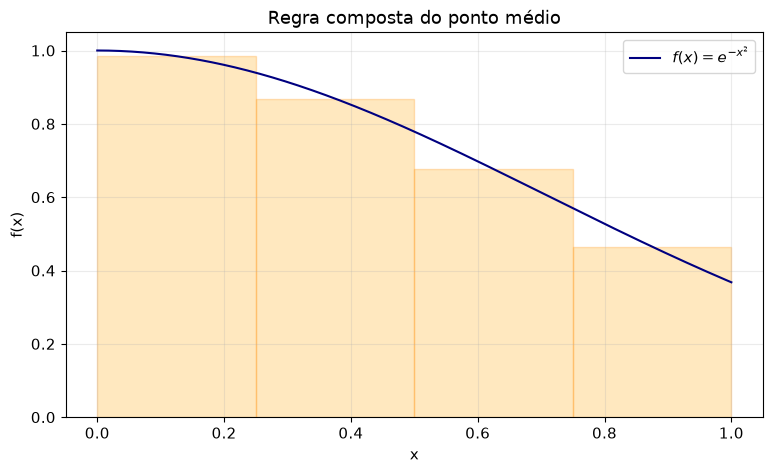

In [3]:
# Visualização dos retângulos do ponto médio
x = np.linspace(a, b, 500)
h = (b-a)/n
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label=r"$f(x)=e^{-x^2}$")
for i in range(n):
    left = a + i*h
    mid = left + h/2
    ax.bar(mid, f(mid), width=h, align="center", alpha=0.25,
           edgecolor="darkorange", color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta do ponto médio")
ax.legend(); ax.grid(alpha=0.25); plt.show()


## 3. Regra dos trapézios

A regra dos trapézios é um método para aproximar a integral definida quando não queremos ou não conseguimos calcular seu valor exato. A ideia é substituir pequenos trechos da curva por segmentos de reta. Cada segmento, junto com o eixo horizontal, forma um trapézio.

### Como dividir o intervalo

Considere a integral

$$
\int_a^b f(x)\,dx.
$$

Primeiro, dividimos o intervalo $[a,b]$ em $n$ partes de mesma largura. A largura de cada parte é

$$
h=\frac{b-a}{n}.
$$

Os pontos que marcam essa divisão são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

Em cada subintervalo $[x_i,x_{i+1}]$, usamos os valores da função nos dois extremos, $f(x_i)$ e $f(x_{i+1})$, para construir um trapézio.

### Área de um trapézio

A área de um trapézio é calculada pela média das alturas multiplicada pela largura da base. Assim, no subintervalo $[x_i,x_{i+1}]$, a área aproximada é

$$
A_i\approx
\frac{f(x_i)+f(x_{i+1})}{2}\,h.
$$

Fazemos esse cálculo em todos os subintervalos e somamos as áreas. A regra composta dos trapézios é

$$
T_n
=
\frac{h}{2}
\sum_{i=0}^{n-1}
\left[f(x_i)+f(x_{i+1})\right].
$$

Reunindo os termos repetidos, obtemos a forma equivalente

$$
T_n
=
h\left[
\frac{f(x_0)+f(x_n)}{2}
+
\sum_{i=1}^{n-1}f(x_i)
\right].
$$

Nessa fórmula, os valores da função nos extremos do intervalo, $f(x_0)$ e $f(x_n)$, são multiplicados por $1/2$. Os valores nos pontos internos, $f(x_1),\ldots,f(x_{n-1})$, são somados com peso completo.

### Exemplo passo a passo

Vamos aproximar

$$
\int_0^2 x^2\,dx
$$

usando a regra dos trapézios com $n=2$ subintervalos.

**1. Calculamos a largura de cada subintervalo:**

$$
h=\frac{2-0}{2}=1.
$$

**2. Identificamos os pontos da divisão:**

$$
x_0=0,\qquad x_1=1,\qquad x_2=2.
$$

**3. Calculamos os valores da função $f(x)=x^2$ nesses pontos:**

$$
f(0)=0,\qquad f(1)=1,\qquad f(2)=4.
$$

**4. Substituímos os valores na fórmula:**

$$
T_2
=
1\left[
\frac{f(0)+f(2)}{2}+f(1)
\right].
$$

Portanto,

$$
T_2
=
1\left[
\frac{0+4}{2}+1
\right]
=3.
$$

Assim, a regra dos trapézios fornece a aproximação

$$
\int_0^2 x^2\,dx\approx 3.
$$

Para comparar, podemos calcular o valor exato:

$$
\int_0^2 x^2\,dx
=
\left[\frac{x^3}{3}\right]_0^2
=
\frac{8}{3}
\approx 2{,}667.
$$

A aproximação foi $3$, enquanto o valor exato é aproximadamente $2{,}667$. Portanto, neste exemplo, a regra dos trapézios **superestimou** a integral.

### Como interpretar o resultado geometricamente

Em cada subintervalo, o segmento de reta aproxima a curva. A área do trapézio pode ficar acima ou abaixo da área real sob a curva. Ao somar todos os trapézios, obtemos a aproximação da integral:

$$
\int_a^b f(x)\,dx\approx T_n.
$$

Se a função estiver acima do eixo $x$, as áreas contribuem positivamente. Se estiver abaixo do eixo $x$, elas contribuem negativamente, assim como ocorre na integral definida.

### Precisão e efeito do número de subintervalos

Para funções suficientemente suaves, o erro global da regra dos trapézios é da ordem de $h^2$. Isso significa que, em geral, diminuir $h$ melhora a aproximação.

Como $h=(b-a)/n$, aumentar $n$ reduz a largura dos subintervalos. Quando dobramos $n$, a largura $h$ é reduzida pela metade e o erro tende a diminuir aproximadamente por um fator de quatro. Esse comportamento é esperado quando a função é suave e a malha já é suficientemente fina.

### O que a curvatura pode indicar

A curvatura da função ajuda a prever o sentido do erro:

- Se $f''(x)>0$ em todo o intervalo, a função é convexa. Os segmentos de reta tendem a ficar acima da curva, e a regra dos trapézios tende a **superestimar** a integral.
- Se $f''(x)<0$ em todo o intervalo, a função é côncava. Os segmentos de reta tendem a ficar abaixo da curva, e a regra tende a **subestimar** a integral.

Essa previsão pressupõe que a função mantenha a mesma concavidade em todo o intervalo. Se a curvatura mudar, diferentes regiões podem contribuir para o erro em sentidos opostos.

### Em resumo

A regra dos trapézios aproxima a curva por segmentos de reta e soma as áreas dos trapézios formados. É simples de aplicar e funciona especialmente bem quando a função varia suavemente. Aumentar o número de subintervalos costuma melhorar a aproximação, mas a precisão também depende do comportamento da função.

In [4]:
def trapezios(f, a, b, n):
    """Aproxima integral de f em [a,b] pela regra composta dos trapézios."""
    if n < 1:
        raise ValueError("n deve ser um inteiro positivo")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

print("Trapézios:", trapezios(f, a, b, n))


Trapézios: 0.7429840978003812


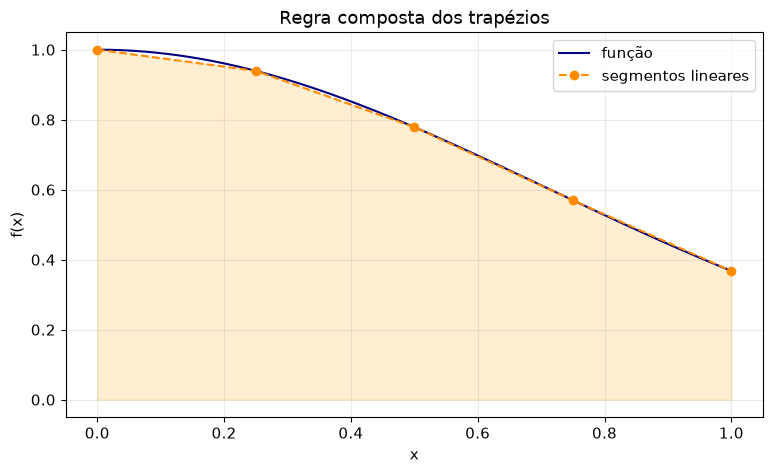

In [5]:
# Segmentos lineares usados pelos trapézios
x = np.linspace(a, b, 500)
xi = np.linspace(a, b, n+1)
fig, ax = plt.subplots()
ax.plot(x, f(x), color="navy", label="função")
ax.plot(xi, f(xi), "o--", color="darkorange", label="segmentos lineares")
ax.fill_between(xi, f(xi), alpha=0.18, color="orange")
ax.set(xlabel="x", ylabel="f(x)", title="Regra composta dos trapézios")
ax.legend(); ax.grid(alpha=0.25); plt.show()


## 4. Regra de Simpson 1/3

A regra de Simpson 1/3 é uma técnica para aproximar uma integral definida. Sua ideia é aproximar a curva por parábolas e, em seguida, calcular a área sob essas parábolas.

Na regra dos trapézios, cada trecho da curva é aproximado por uma reta. Simpson usa uma parábola, que pode representar melhor a curvatura da função. Para construir cada parábola, usamos três pontos consecutivos: o início, o ponto médio e o fim de um trecho.

### 4.1 Como dividir o intervalo

Considere a integral

$$
\int_a^b f(x)\,dx.
$$

Dividimos o intervalo $[a,b]$ em $n$ subintervalos de mesma largura. A largura de cada subintervalo é

$$
h=\frac{b-a}{n}.
$$

Os pontos da divisão são

$$
x_i=a+ih,\qquad i=0,1,\ldots,n.
$$

A regra de Simpson trabalha com **dois subintervalos por vez**. Para cada grupo, usamos três pontos para ajustar uma parábola:

$$
x_0,\quad x_1,\quad x_2.
$$

Por esse motivo, o número total de subintervalos, $n$, precisa ser **par**.

Por exemplo, se $n=4$, os pontos são $x_0,x_1,x_2,x_3,x_4$. Podemos formar dois grupos:

$$
(x_0,x_1,x_2)
\qquad\text{e}\qquad
(x_2,x_3,x_4).
$$

Cada grupo define uma parábola. O ponto $x_2$ é compartilhado pelos dois grupos.

### 4.2 Fórmula para um grupo de dois subintervalos

Para aproximar a integral em um grupo formado pelos pontos $x_0$, $x_1$ e $x_2$, usamos:

$$
\int_{x_0}^{x_2} f(x)\,dx
\approx
\frac{h}{3}
\left[
f(x_0)+4f(x_1)+f(x_2)
\right].
$$

O ponto central recebe peso $4$, enquanto os pontos das extremidades recebem peso $1$. Esses pesos vêm da fórmula de integração da parábola que passa pelos três pontos.

### 4.3 Fórmula composta

Quando o intervalo tem mais de dois subintervalos, aplicamos a fórmula em cada grupo de dois subintervalos e somamos as aproximações. O resultado é a regra composta de Simpson 1/3:

$$
S_n
=
\frac{h}{3}
\left[
f(x_0)+f(x_n)
+
4\sum_{\substack{i=1\\ i\text{ ímpar}}}^{n-1} f(x_i)
+
2\sum_{\substack{i=2\\ i\text{ par}}}^{n-2} f(x_i)
\right].
$$

Os pesos seguem o padrão

$$
1,\ 4,\ 2,\ 4,\ 2,\ \ldots,\ 4,\ 1.
$$

Isso significa que:

- os valores nos extremos, $f(x_0)$ e $f(x_n)$, recebem peso $1$;
- os valores nos índices ímpares recebem peso $4$;
- os valores internos nos índices pares recebem peso $2$.

Depois de multiplicar a soma ponderada por $h/3$, obtemos a aproximação da integral:

$$
\int_a^b f(x)\,dx\approx S_n.
$$

### 4.4 Exemplo passo a passo

Vamos aproximar

$$
\int_0^2 x^3\,dx
$$

usando $n=2$ subintervalos.

**Passo 1 — Calcular a largura dos subintervalos**

$$
h=\frac{b-a}{n}
=\frac{2-0}{2}
=1.
$$

**Passo 2 — Identificar os pontos**

Como o intervalo começa em $0$ e cada passo tem largura $1$, temos:

$$
x_0=0,\qquad x_1=1,\qquad x_2=2.
$$

**Passo 3 — Calcular os valores da função**

Para $f(x)=x^3$:

$$
f(x_0)=f(0)=0,
\qquad
f(x_1)=f(1)=1,
\qquad
f(x_2)=f(2)=8.
$$

**Passo 4 — Aplicar a fórmula**

Como temos um único grupo de dois subintervalos:

$$
S_2
=
\frac{h}{3}
\left[
f(x_0)+4f(x_1)+f(x_2)
\right].
$$

Substituindo $h=1$ e os valores da função:

$$
S_2
=
\frac{1}{3}
\left[
0+4(1)+8
\right]
=
\frac{12}{3}
=
4.
$$

Assim, a regra de Simpson fornece

$$
\int_0^2 x^3\,dx\approx 4.
$$

Neste exemplo, a aproximação coincide com o valor exato:

$$
\int_0^2 x^3\,dx
=
\left[\frac{x^4}{4}\right]_0^2
=
4.
$$

### 4.5 Quando Simpson fornece um resultado exato?

A regra de Simpson 1/3 integra exatamente polinômios de grau até 3, desde que os cálculos sejam feitos sem erros de arredondamento. Isso inclui funções como

$$
f(x)=1,\qquad f(x)=x,\qquad f(x)=x^2,\qquad f(x)=x^3.
$$

Para outras funções, o resultado geralmente é uma aproximação. Ainda assim, Simpson costuma apresentar boa precisão quando a função varia suavemente.

### 4.6 Precisão e erro

Para funções com derivadas contínuas até a quarta ordem, o erro global da regra composta de Simpson é da ordem de $h^4$. Em termos simples, isso indica que o erro tende a diminuir rapidamente quando reduzimos o tamanho dos subintervalos.

Se dobrarmos o número de subintervalos, $n$, a largura $h$ será reduzida pela metade. Em condições adequadas, o erro de Simpson tende a ficar aproximadamente $16$ vezes menor, pois

$$
\left(\frac{h}{2}\right)^4=\frac{h^4}{16}.
$$

Esse fator é uma tendência teórica, válida quando a função é suficientemente suave e a malha está em uma faixa adequada. Descontinuidades, oscilações ou ruído nos dados podem alterar o comportamento observado.

### Para lembrar

- Simpson aproxima a curva por parábolas.
- Cada parábola é ajustada usando três pontos consecutivos.
- Cada grupo cobre dois subintervalos; por isso, $n$ deve ser par.
- Os pesos da fórmula seguem o padrão $1,4,2,4,\ldots,2,4,1$.
- A regra é exata para polinômios de grau até 3.
- Para funções suaves, o erro global é da ordem de $h^4$.

In [6]:
def simpson(f, a, b, n):
    """Aproxima integral pela regra composta de Simpson 1/3 (n par)."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Simpson 1/3 requer n par e n >= 2")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h/3) * (y[0] + y[-1]
                    + 4*np.sum(y[1:-1:2])
                    + 2*np.sum(y[2:-1:2]))

print("Simpson:", simpson(f, a, b, n))


Simpson: 0.7468553797909873


### Por que Simpson exige um número par de subintervalos?

A parábola é ajustada usando três nós consecutivos: início, ponto médio e fim de um bloco. Cada bloco cobre dois subintervalos. Assim, os subintervalos precisam ser agrupados em pares. Se houver um número ímpar de subintervalos, a implementação acima interrompe o cálculo para evitar aplicar uma fórmula incompatível.


## 5. Comparação das regras em um exemplo

Para \(f(x)=e^{-x^2}\) em \([0,1]\), não precisamos conhecer uma antiderivada elementar. `scipy.integrate.quad` será usado apenas como valor de referência de alta precisão; as três regras implementadas são independentes do SciPy.


In [7]:
from scipy.integrate import quad

I_ref, erro_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Referência (quad): {I_ref:.12f}")
print(f"Estimativa de erro do quad: {erro_quad:.2e}")

linhas = []
for n in [2, 4, 8, 16, 32, 64]:
    vals = {
        "n": n,
        "Ponto médio": ponto_medio(f, 0, 1, n),
        "Trapézios": trapezios(f, 0, 1, n),
        "Simpson": simpson(f, 0, 1, n),
    }
    for regra in ["Ponto médio", "Trapézios", "Simpson"]:
        vals["Erro " + regra] = abs(vals[regra] - I_ref)
    linhas.append(vals)

import pandas as pd
pd.DataFrame(linhas).set_index("n").style.format("{:.3e}")


Referência (quad): 0.746824132812
Estimativa de erro do quad: 8.29e-15


,Ponto médio,Trapézios,Simpson,Erro Ponto médio,Erro Trapézios,Erro Simpson
n,,,,,,
2,7.546e-01,7.314e-01,7.472e-01,7.774e-03,1.545e-02,3.563e-04
4,7.487e-01,7.430e-01,7.469e-01,1.923e-03,3.840e-03,3.125e-05
8,7.473e-01,7.459e-01,7.468e-01,4.794e-04,9.585e-04,1.988e-06
16,7.469e-01,7.466e-01,7.468e-01,1.198e-04,2.395e-04,1.246e-07
32,7.469e-01,7.468e-01,7.468e-01,2.994e-05,5.988e-05,7.795e-09
64,7.468e-01,7.468e-01,7.468e-01,7.485e-06,1.497e-05,4.872e-10


## 6. Visualização da convergência


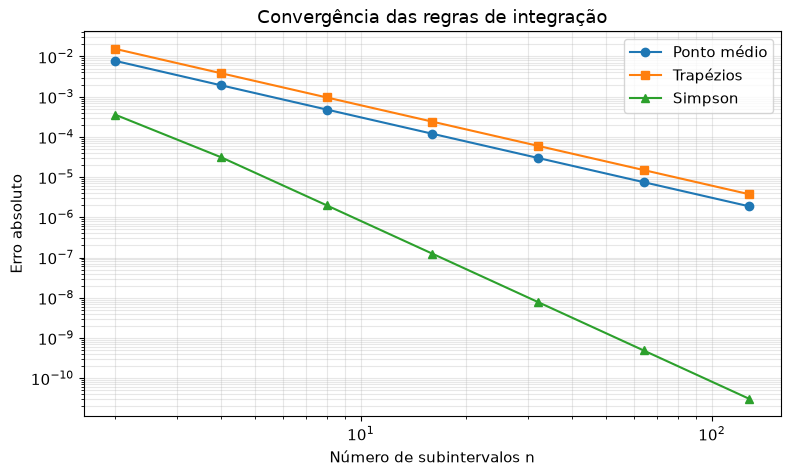

In [8]:
ns = np.array([2, 4, 8, 16, 32, 64, 128])
err_m = np.array([abs(ponto_medio(f, 0, 1, int(k))-I_ref) for k in ns])
err_t = np.array([abs(trapezios(f, 0, 1, int(k))-I_ref) for k in ns])
err_s = np.array([abs(simpson(f, 0, 1, int(k))-I_ref) for k in ns])

plt.loglog(ns, err_m, "o-", label="Ponto médio")
plt.loglog(ns, err_t, "s-", label="Trapézios")
plt.loglog(ns, err_s, "^-", label="Simpson")
plt.xlabel("Número de subintervalos n")
plt.ylabel("Erro absoluto")
plt.title("Convergência das regras de integração")
plt.grid(True, which="both", alpha=0.3); plt.legend(); plt.show()


## 7. Estimativa de erro por refinamento (Richardson)

Se uma aproximação tem erro dominante proporcional a \(h^p\), então refinar a malha (usar \(2n\) subintervalos) permite estimar o erro da aproximação mais fina por

\[
|I-I_{2n}|\approx \frac{|I_{2n}-I_n|}{2^p-1}.
\]

Use \(p=2\) para ponto médio e trapézios e \(p=4\) para Simpson, desde que a função seja suave e estejamos na região assintótica. É uma estimativa prática, não um limite rigoroso universal.


In [9]:
def estimativa_richardson(valor_n, valor_2n, ordem):
    return abs(valor_2n - valor_n) / (2**ordem - 1)

n = 8
for nome, regra, p in [("Ponto médio", ponto_medio, 2),
                       ("Trapézios", trapezios, 2),
                       ("Simpson", simpson, 4)]:
    I_n = regra(f, 0, 1, n)
    I_2n = regra(f, 0, 1, 2*n)
    erro_estimado = estimativa_richardson(I_n, I_2n, p)
    erro_real = abs(I_2n - I_ref)
    print(f"{nome:12s}: estimado={erro_estimado:.3e} | real da malha 2n={erro_real:.3e}")


Ponto médio : estimado=1.199e-04 | real da malha 2n=1.198e-04
Trapézios   : estimado=2.397e-04 | real da malha 2n=2.395e-04
Simpson     : estimado=1.242e-07 | real da malha 2n=1.246e-07


## 8. Exemplo com integral conhecida

Vamos integrar \(f(x)=x^3\) em \([0,2]\). O valor exato é

\[
\int_0^2 x^3\,dx=\left.\frac{x^4}{4}\right|_0^2=4.
\]

Simpson deve recuperar esse valor (a menos de arredondamento), pois a função é um polinômio de grau 3.


In [10]:
g = lambda x: x**3
I_exato = 4.0
for nome, regra, n_teste in [("Ponto médio", ponto_medio, 8),
                             ("Trapézios", trapezios, 8),
                             ("Simpson", simpson, 8)]:
    aproxima = regra(g, 0, 2, n_teste)
    print(f"{nome:12s}: {aproxima:.12f} | erro = {abs(aproxima-I_exato):.3e}")


Ponto médio : 3.968750000000 | erro = 3.125e-02
Trapézios   : 4.062500000000 | erro = 6.250e-02
Simpson     : 4.000000000000 | erro = 0.000e+00


## 9. Integração a partir de dados tabelados

Às vezes não temos uma fórmula para \(f\), apenas medições \((x_i,y_i)\). Para malha uniforme, podemos aplicar trapézios ou Simpson diretamente aos dados. Simpson requer número par de subintervalos.

Deslocamento aproximado (trapézios): 8.4500 m


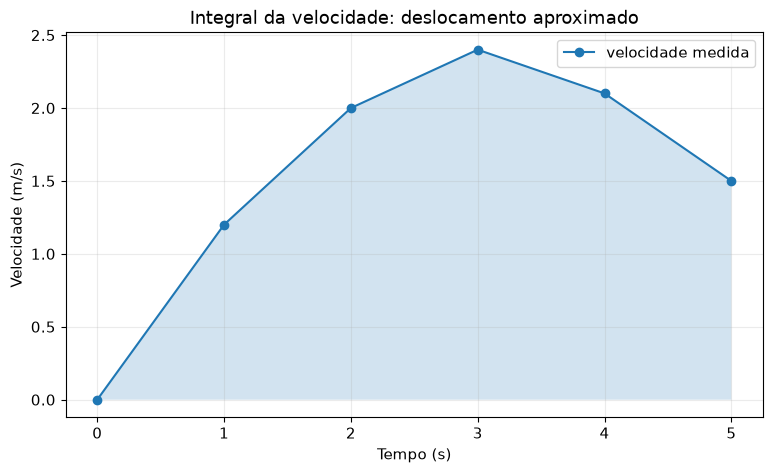

In [11]:
# Exemplo de medições (valores sintéticos): velocidade ao longo do tempo
x_dados = np.array([0, 1, 2, 3, 4, 5], dtype=float)
v_dados = np.array([0.0, 1.2, 2.0, 2.4, 2.1, 1.5])

# Trapézios em dados igualmente espaçados
deslocamento_trap = np.trapezoid(v_dados, x_dados)
print(f"Deslocamento aproximado (trapézios): {deslocamento_trap:.4f} m")

# Visualização das medições
plt.plot(x_dados, v_dados, "o-", label="velocidade medida")
plt.fill_between(x_dados, v_dados, alpha=0.2)
plt.xlabel("Tempo (s)"); plt.ylabel("Velocidade (m/s)")
plt.title("Integral da velocidade: deslocamento aproximado")
plt.grid(alpha=0.25); plt.legend(); plt.show()


## 10. Cuidados práticos

- **Escolha da regra:** Simpson costuma ser eficiente para funções suaves; trapézios é simples e funciona diretamente com dados tabelados.
- **Número de subintervalos:** Simpson 1/3 requer \(n\) par.
- **Regularidade:** descontinuidades, quinas e oscilações podem reduzir a ordem esperada de convergência.
- **Dados experimentais:** ruído nas medições não desaparece só porque usamos mais pontos; considere incerteza e resolução do instrumento.
- **Arredondamento:** aumentar \(n\) indefinidamente pode fazer erros de arredondamento se tornarem relevantes.
- **Unidades:** se \(f\) tem unidade de m/s e \(x\) está em s, a integral tem unidade de m.
- **Sinal:** uma integral pode ser negativa; não confundir integral assinada com área geométrica total.


## 11. Atividade guiada

Considere duas funções senoidais distintas e calcule:

1. Calcule a integral exata manualmente.
2. Aproxime usando as três regras para \(n=2,4,8,16\).
3. Monte uma tabela de erros absolutos.
4. Faça um gráfico do erro em função de \(n\), com escala log-log.
5. Compare o comportamento observado com as ordens teóricas.
6. Explique qual regra foi mais eficiente neste exemplo e por quê.


In [12]:
# Comece o exercício aqui; use células adicionais para responder.
f_atividade = lambda x: np.sin(x)
a_atividade, b_atividade = 0.0, np.pi
I_atividade_exata = 2.0

for n in [2, 4, 8, 16]:
    print(n,
          "M=", ponto_medio(f_atividade, a_atividade, b_atividade, n),
          "T=", trapezios(f_atividade, a_atividade, b_atividade, n),
          "S=", simpson(f_atividade, a_atividade, b_atividade, n))


2 M= 2.221441469079183 T= 1.5707963267948966 S= 2.0943951023931953
4 M= 2.0523443059540623 T= 1.8961188979370398 S= 2.0045597549844207
8 M= 2.012909085599128 T= 1.9742316019455508 S= 2.0002691699483877
16 M= 2.00321637816795 T= 1.9935703437723395 S= 2.0000165910479355


## Resolução da atividade guiada

### Funções escolhidas

| | Função | Intervalo | Integral exata |
|---|---|---|---|
| $f_1$ | $\sin x$ | $[0,\pi]$ | $2$ |
| $f_2$ | $\sin(5x)$ | $[0,\pi]$ | $2/5$ |

$f_1$ é a função da célula inicial da atividade. Para $f_2$ mantivemos o intervalo e a amplitude e mudamos só a frequência: $\sin(5x)$ oscila cinco vezes mais rápido. Como o intervalo é o mesmo, para um mesmo $n$ as duas funções usam o mesmo passo $h=\pi/n$, e qualquer diferença nos erros vem apenas do quanto a função oscila.

### 1. Integral exata (cálculo manual)

**$f_1(x)=\sin x$ em $[0,\pi]$.** Uma antiderivada de $\sin x$ é $-\cos x$:

$$
\int_0^{\pi}\sin x\,dx=\Big[-\cos x\Big]_0^{\pi}=-\cos\pi+\cos 0=1+1=2.
$$

**$f_2(x)=\sin(5x)$ em $[0,\pi]$.** Com a substituição $u=5x$, temos $du=5\,dx$; quando $x=0$, $u=0$, e quando $x=\pi$, $u=5\pi$:

$$
\int_0^{\pi}\sin(5x)\,dx=\frac15\int_0^{5\pi}\sin u\,du=\frac15\Big[-\cos u\Big]_0^{5\pi}
=\frac{-\cos 5\pi+\cos 0}{5}=\frac{1+1}{5}=\frac25=0{,}4,
$$

pois $\cos 5\pi=\cos(\pi+4\pi)=\cos\pi=-1$.

**Leitura como área com sinal.** Em $[0,\pi]$, $\sin(5x)$ forma 5 meias-ondas de largura $\pi/5$: três acima do eixo e duas abaixo. Cada meia-onda tem área de módulo

$$
\int_0^{\pi/5}\sin(5x)\,dx=\frac{2}{5},
$$

então a integral vale $3\cdot\frac25-2\cdot\frac25=\frac25$: as duas meias-ondas negativas cancelam duas das positivas e sobra uma. A área geométrica total seria $5\cdot\frac25=2$, igual à integral de $f_1$, mas a integral (acumulação líquida) é cinco vezes menor. É o caso de que a seção 1 fala: integral definida não é área total.

In [13]:
# Atividade guiada: funções, intervalo e valores exatos
from scipy.integrate import quad
import pandas as pd

a_at, b_at = 0.0, np.pi
funcoes = {
    "f1(x) = sin(x)":  {"f": lambda x: np.sin(x),   "k": 1, "exata": 2.0},
    "f2(x) = sin(5x)": {"f": lambda x: np.sin(5*x), "k": 5, "exata": 2/5},
}
ns_atividade = [2, 4, 8, 16]
regras = {"Ponto médio": ponto_medio, "Trapézios": trapezios, "Simpson": simpson}

# Conferência do cálculo manual com o quad (só verificação; as regras não usam o SciPy)
for nome, dados in funcoes.items():
    I_quad, _ = quad(dados["f"], a_at, b_at, limit=200)
    print(f"{nome:16s} exata = {dados['exata']:.12f} | quad = {I_quad:.12f} "
          f"| diferença = {abs(I_quad - dados['exata']):.1e}")

f1(x) = sin(x)   exata = 2.000000000000 | quad = 2.000000000000 | diferença = 0.0e+00
f2(x) = sin(5x)  exata = 0.400000000000 | quad = 0.400000000000 | diferença = 0.0e+00


O gráfico mostra as duas funções com a área positiva em azul e a negativa em vermelho. Os pontos pretos são os nós dos trapézios e de Simpson com $n=2$ ($x=0,\ \pi/2,\ \pi$). Repare que eles leem os **mesmos valores** $(0,\ 1,\ 0)$ nas duas funções: com essa malha, as regras não têm como distinguir $\sin(5x)$ de $\sin x$. O efeito disso aparece nas tabelas.

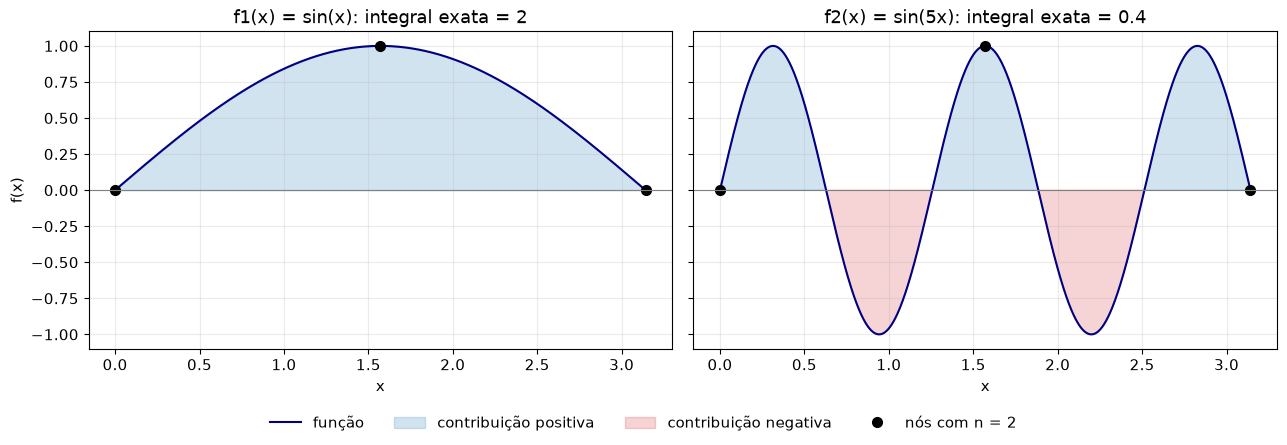

In [14]:
# As duas funções, a área com sinal e os nós da malha com n = 2
x_fino = np.linspace(a_at, b_at, 1000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (nome, dados) in zip(axes, funcoes.items()):
    y = dados["f"](x_fino)
    ax.plot(x_fino, y, color="navy", label=nome)
    ax.fill_between(x_fino, y, where=y >= 0, interpolate=True, color="tab:blue", alpha=0.2,
                    label="contribuição positiva")
    ax.fill_between(x_fino, y, where=y < 0, interpolate=True, color="tab:red", alpha=0.2,
                    label="contribuição negativa")
    x_nos = np.linspace(a_at, b_at, 3)
    ax.plot(x_nos, dados["f"](x_nos), "ko", ms=7, label="nós com n = 2")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(title=f"{nome}: integral exata = {dados['exata']:g}", xlabel="x")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("f(x)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, ["função"] + labels[1:], loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

### 2. Aproximações com $n=2,4,8,16$

Usamos as funções `ponto_medio`, `trapezios` e `simpson` implementadas nas seções 2 a 4, sem mudança. Todos os valores de $n$ pedidos são pares, então Simpson pode ser aplicado em todos.

In [15]:
# Item 2: aproximações das três regras
linhas = []
for nome, dados in funcoes.items():
    for n in ns_atividade:
        linha = {"Função": nome, "n": n, "h": (b_at - a_at) / n}
        for regra, metodo in regras.items():
            linha[regra] = metodo(dados["f"], a_at, b_at, n)
        linha["Exata"] = dados["exata"]
        linhas.append(linha)

aprox = pd.DataFrame(linhas).set_index(["Função", "n"])
aprox.style.format({col: ("{:.4f}" if col == "h" else "{:.10f}") for col in aprox.columns})

### 3. Tabela de erros absolutos

Erro absoluto $=|\text{aproximação}-\text{valor exato}|$.

In [16]:
# Item 3: erros absolutos
erros = aprox[list(regras)].sub(aprox["Exata"], axis=0).abs()
erros.style.format("{:.3e}")

**Resposta do grupo (itens 2 e 3).**

- **$f_1=\sin x$.** As três regras se aproximam de $2$ desde $n=2$, e Simpson é a mais precisa em todos os $n$: com $n=16$ o erro é $1{,}7\times10^{-5}$, contra $3{,}2\times10^{-3}$ do ponto médio e $6{,}4\times10^{-3}$ dos trapézios. Os trapézios ficam sempre **abaixo** de $2$ e o ponto médio sempre **acima**. Isso bate com a seção 3: $\sin x$ é côncava em $[0,\pi]$ ($f''=-\sin x\le 0$), então os segmentos de reta passam por baixo da curva e os trapézios subestimam. O erro do ponto médio é quase exatamente metade do erro dos trapézios, com sinal oposto.
- **$f_2=\sin(5x)$.** Com $n=2$ e $n=4$ as aproximações não servem: os erros vão de $0{,}45$ a $2{,}6$, maiores que a própria integral ($0{,}4$). Com $n=2$, trapézios e Simpson dão **exatamente os mesmos números** de $f_1$ ($1{,}5707963268$ e $2{,}0943951024$), porque os nós leem os mesmos valores nas duas funções (gráfico acima); o ponto médio chega a errar o sinal ($-2{,}22$). Com $n=4$, Simpson é a **pior** das três (erro $1{,}36$, contra $0{,}45$ do ponto médio). A partir de $n=8$ a ordem esperada se estabelece e, com $n=16$, Simpson volta à frente: $2{,}3\times10^{-3}$, contra $1{,}7\times10^{-2}$ (ponto médio) e $3{,}3\times10^{-2}$ (trapézios).
- **Mesmo $h$, erros diferentes.** Com $n=16$, os erros de $f_2$ são cerca de 5 vezes os de $f_1$ no ponto médio e nos trapézios, e cerca de 140 vezes em Simpson. O passo é o mesmo; o que muda é a curvatura: as derivadas de $\sin(5x)$ são multiplicadas por $5$, $25$, $125$, $625$…, e são elas que entram nas fórmulas de erro (ver o complemento depois do item 5).

### 4. Gráfico do erro em função de $n$ (escala log-log)

Se o erro se comporta como $E\approx C\,h^p=C\left(\frac{b-a}{n}\right)^p$, então

$$
\log E\approx \log\!\big(C\,(b-a)^p\big)-p\,\log n,
$$

ou seja, em escala log-log o erro vira uma **reta de inclinação $-p$**. As linhas pretas são retas de referência com inclinação $-2$ (tracejada) e $-4$ (pontilhada), ancoradas no ponto $n=16$ dos trapézios e de Simpson.

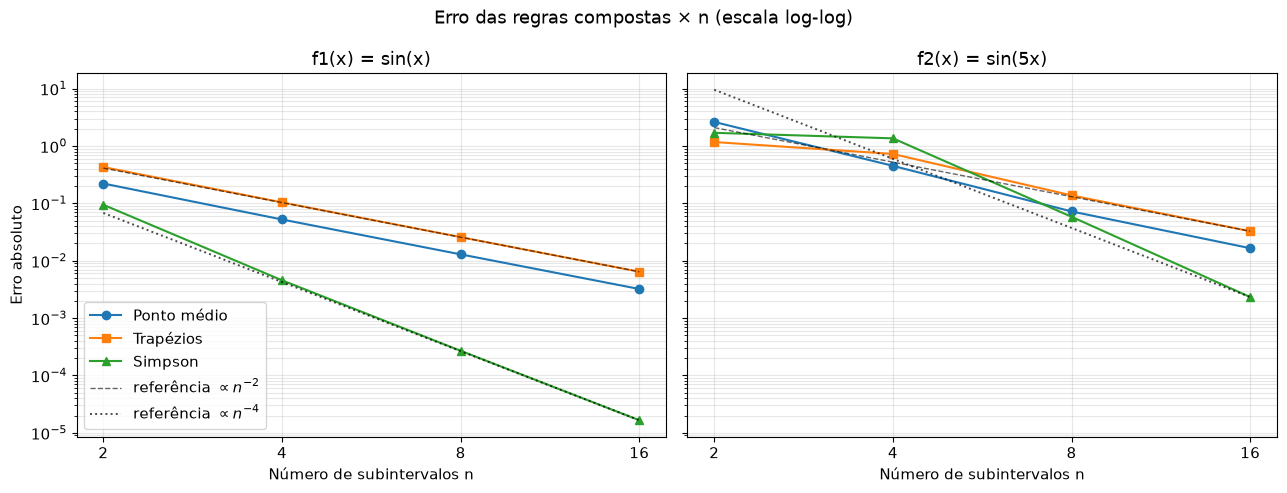

In [17]:
# Item 4: erro × n em escala log-log, uma figura por função
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
estilos = {"Ponto médio": "o-", "Trapézios": "s-", "Simpson": "^-"}
ns = np.array(ns_atividade, dtype=float)

for ax, nome in zip(axes, funcoes):
    e = erros.loc[nome]
    for regra in regras:
        ax.loglog(ns, e[regra], estilos[regra], label=regra)
    ax.loglog(ns, e.loc[16, "Trapézios"] * (ns / 16) ** -2, "k--", lw=1, alpha=0.6,
              label=r"referência $\propto n^{-2}$")
    ax.loglog(ns, e.loc[16, "Simpson"] * (ns / 16) ** -4, "k:", lw=1.4, alpha=0.7,
              label=r"referência $\propto n^{-4}$")
    ax.set_xticks(ns, [str(int(k)) for k in ns])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set(title=nome, xlabel="Número de subintervalos n")
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("Erro absoluto")
axes[0].legend(loc="lower left")
fig.suptitle("Erro das regras compostas × n (escala log-log)")
plt.tight_layout(); plt.show()

**Resposta do grupo (item 4).** Para $f_1$, as três curvas já são retas desde $n=2$: ponto médio e trapézios paralelos à referência $n^{-2}$ (o ponto médio um pouco abaixo, por ter metade do erro), Simpson paralelo à referência $n^{-4}$, bem mais inclinada. Para $f_2$, o trecho de $n=2$ a $n=4$ é quase horizontal nos trapézios e em Simpson: dobrar $n$ quase não reduziu o erro. Só de $n=8$ em diante as curvas acompanham as retas de referência.

### 5. Comparação com as ordens teóricas

Se $E_n\approx C\,h^p$, dobrar $n$ divide $h$ por 2 e o erro por $2^p$. A **ordem observada** entre duas malhas consecutivas é então

$$
p_{\text{obs}}=\log_2\!\left(\frac{E_n}{E_{2n}}\right).
$$

A teoria das seções 2 a 4 prevê $p=2$ para o ponto médio e os trapézios (erro dividido por 4 a cada vez que $n$ dobra) e $p=4$ para Simpson (erro dividido por 16).

In [18]:
# Item 5: ordem observada p = log2(E_n / E_2n)
linhas = []
for nome in funcoes:
    e = erros.loc[nome]
    for n0, n1 in zip(ns_atividade[:-1], ns_atividade[1:]):
        linha = {"Função": nome, "Passagem": f"n = {n0} → {n1}"}
        for regra in regras:
            linha[regra] = np.log2(e.loc[n0, regra] / e.loc[n1, regra])
        linhas.append(linha)
linhas.append({"Função": "Ordem teórica", "Passagem": "h → h/2",
               "Ponto médio": 2, "Trapézios": 2, "Simpson": 4})

ordens = pd.DataFrame(linhas).set_index(["Função", "Passagem"])
ordens.style.format("{:.2f}")

**Resposta do grupo (item 5).**

- **$f_1$ confirma a teoria.** As ordens observadas convergem para os valores teóricos: ponto médio $2{,}08\to2{,}02\to2{,}00$, trapézios $2{,}05\to2{,}01\to2{,}00$ e Simpson $4{,}37\to4{,}08\to4{,}02$. Na prática, cada vez que $n$ dobra, o erro dos trapézios cai por 4 (de $2{,}58\times10^{-2}$ para $6{,}43\times10^{-3}$ entre $n=8$ e $16$) e o de Simpson cai por 16 (de $2{,}69\times10^{-4}$ para $1{,}66\times10^{-5}$). O desvio em $n=2\to4$ é pequeno e vem dos termos de ordem mais alta do erro, que ainda pesam quando $h$ é grande.
- **$f_2$ só segue a teoria com malha fina.** De $n=2$ para $4$, as ordens são $2{,}54$, $0{,}69$ e $0{,}32$: os trapézios e Simpson praticamente não melhoraram. As ordens de 2 e 4 são **assintóticas**: valem quando $h$ é pequeno em relação à escala em que a função muda. O período de $\sin(5x)$ é $2\pi/5\approx1{,}26$; com $n=2$ ou $4$ ($h=1{,}57$ ou $0{,}79$) há menos de dois subintervalos por período, e a malha simplesmente não enxerga a oscilação. Com $n=8$ e $16$ (3,2 e 6,4 subintervalos por período) as ordens chegam a $2{,}13$, $2{,}08$ e $4{,}65$, perto do previsto. É o aviso das seções 2 a 4: o fator 4 ou 16 é uma tendência teórica, que **oscilações** podem atrasar.

### Complemento do grupo: o tamanho do erro previsto pelas fórmulas

As ordens dizem como o erro **cai**; as fórmulas de erro das regras compostas dizem também **quanto** ele vale. Com o erro escrito como aproximação menos valor exato, para algum $\xi\in(a,b)$:

$$
T_n-I=\frac{(b-a)h^2}{12}f''(\xi),\qquad
M_n-I=-\frac{(b-a)h^2}{24}f''(\xi),\qquad
S_n-I=\frac{(b-a)h^4}{180}f^{(4)}(\xi).
$$

Quando $h$ é pequeno, $(b-a)f''(\xi)$ fica muito próximo da integral de $f''$, que sai exata: $\int_a^b f''\,dx=f'(b)-f'(a)$. O mesmo vale para $f^{(4)}$. Isso dá o **termo dominante** do erro:

$$
T_n-I\approx\frac{h^2}{12}\big[f'(b)-f'(a)\big],\qquad
M_n-I\approx-\frac{h^2}{24}\big[f'(b)-f'(a)\big],\qquad
S_n-I\approx\frac{h^4}{180}\big[f'''(b)-f'''(a)\big].
$$

Para $f(x)=\sin(kx)$ em $[0,\pi]$ com $k$ ímpar, $f'(\pi)-f'(0)=-2k$ e $f'''(\pi)-f'''(0)=2k^3$. Logo

$$
T_n-I\approx-\frac{k\,h^2}{6},\qquad M_n-I\approx\frac{k\,h^2}{12},\qquad S_n-I\approx\frac{k^3h^4}{90}.
$$

Três previsões saem daí: (i) $E_M/E_T\approx-1/2$; (ii) no regime assintótico, os erros de $f_2$ ($k=5$) são $5$ vezes os de $f_1$ nas regras de ordem 2 e $5^3=125$ vezes em Simpson; (iii) a previsão só vale quando $h$ é pequeno. A tabela testa as três, estendendo $n$ até 64.

In [19]:
# Complemento: erro real (com sinal) × termo dominante previsto
ns_comp = [2, 4, 8, 16, 32, 64]
linhas = []
for nome, dados in funcoes.items():
    f, k, I = dados["f"], dados["k"], dados["exata"]
    salto_d1 = k*np.cos(k*b_at) - k*np.cos(k*a_at)            # f'(b) - f'(a)
    salto_d3 = -k**3*np.cos(k*b_at) + k**3*np.cos(k*a_at)     # f'''(b) - f'''(a)
    for n in ns_comp:
        h = (b_at - a_at) / n
        eM = ponto_medio(f, a_at, b_at, n) - I
        eT = trapezios(f, a_at, b_at, n) - I
        eS = simpson(f, a_at, b_at, n) - I
        prev_T = h**2 / 12 * salto_d1
        prev_S = h**4 / 180 * salto_d3
        linhas.append({"Função": nome, "n": n,
                       "E_T real": eT, "E_T previsto": prev_T, "T: real/previsto": eT / prev_T,
                       "E_S real": eS, "E_S previsto": prev_S, "S: real/previsto": eS / prev_S,
                       "E_M / E_T": eM / eT})

comp = pd.DataFrame(linhas).set_index(["Função", "n"])
comp.style.format({col: ("{:.3f}" if ("/" in col) else "{:+.3e}") for col in comp.columns})

**Leitura do complemento.** As três previsões se confirmam, e a tabela mostra também **a partir de quando** elas valem.

- **$f_1$.** A previsão acerta o erro dos trapézios com 4 % de diferença já em $n=2$ (razão real/previsto $1{,}044$) e com $0{,}3$ % em $n=8$. Em Simpson a razão cai de $1{,}395$ para $1{,}000$. A razão $E_M/E_T$ vai de $-0{,}516$ a $-0{,}500$: o erro do ponto médio é metade do erro dos trapézios, com o sinal trocado.
- **$f_2$.** Com $n=2$ e $n=4$ a previsão erra até o sinal (razões $-0{,}569$ e $-2{,}568$ em Simpson, por exemplo): com $h$ grande, os termos de ordem mais alta do erro, que crescem com potências ainda maiores de $k=5$, dominam. A partir de $n=16$ as razões ficam a menos de 13 % de 1 e, com $n=64$, a menos de 1 %.
- **Fator entre as funções.** Com $n=64$, o erro dos trapézios de $f_2$ ($-2{,}01\times10^{-3}$) é $5{,}0$ vezes o de $f_1$ ($-4{,}02\times10^{-4}$), e o de Simpson ($8{,}1\times10^{-6}$) é cerca de 126 vezes o de $f_1$ ($6{,}5\times10^{-8}$), praticamente o $5^3=125$ previsto.

Isso explica o item 5 com números: a ordem $p$ só aparece quando o termo dominante domina de fato, e para uma função que oscila mais isso exige um $h$ menor.

### 6. Qual regra foi mais eficiente?

Eficiência é precisão pelo custo, e o custo de uma regra de integração é o **número de avaliações de $f$** (em um problema real, cada avaliação pode ser uma simulação ou uma medição). Com $n$ subintervalos, o ponto médio avalia $f$ em $n$ pontos e os trapézios e Simpson, em $n+1$. A célula abaixo faz duas coisas:

1. procura o menor $n$ com que cada regra atinge erro $\le10^{-6}$ e conta as avaliações gastas;
2. confere a identidade $S_{2m}=\dfrac{T_m+2M_m}{3}$, que explica de onde vem a vantagem de Simpson.

In [20]:
# Item 6a: custo (avaliações de f) para atingir erro <= 1e-6
def menor_n(metodo, f, a, b, exata, tol, inicio=1, passo=1, n_max=100_000):
    n = inicio
    while abs(metodo(f, a, b, n) - exata) > tol:
        n += passo
        if n > n_max:
            return None
    return n

tol = 1e-6
linhas = []
for nome, dados in funcoes.items():
    for regra, metodo in regras.items():
        inicio, passo = (2, 2) if regra == "Simpson" else (1, 1)   # Simpson só aceita n par
        n = menor_n(metodo, dados["f"], a_at, b_at, dados["exata"], tol, inicio, passo)
        avaliacoes = n if regra == "Ponto médio" else n + 1
        linhas.append({"Função": nome, "Regra": regra, "Menor n": n, "Avaliações de f": avaliacoes})
custo = pd.DataFrame(linhas).set_index(["Função", "Regra"])
display(custo)

# Item 6b: Simpson é uma média ponderada de trapézios e ponto médio
print("Conferência de S_2m = (T_m + 2 M_m) / 3")
for nome, dados in funcoes.items():
    for m in [1, 2, 4, 8]:
        combinacao = (trapezios(dados["f"], a_at, b_at, m)
                      + 2 * ponto_medio(dados["f"], a_at, b_at, m)) / 3
        s2m = simpson(dados["f"], a_at, b_at, 2 * m)
        print(f"  {nome:16s} m = {m}: (T_m + 2M_m)/3 = {combinacao:+.12f} | "
              f"S_{2*m:<2d} = {s2m:+.12f} | diferença = {abs(combinacao - s2m):.1e}")

Menor n  Avaliações de f
Função          Regra                                
f1(x) = sin(x)  Ponto médio      907              907
                Trapézios       1283             1284
                Simpson           34               35
f2(x) = sin(5x) Ponto médio     2028             2028
                Trapézios       2868             2869
                Simpson          108              109

Conferência de S_2m = (T_m + 2 M_m) / 3
  f1(x) = sin(x)   m = 1: (T_m + 2M_m)/3 = +2.094395102393 | S_2  = +2.094395102393 | diferença = 0.0e+00
  f1(x) = sin(x)   m = 2: (T_m + 2M_m)/3 = +2.004559754984 | S_4  = +2.004559754984 | diferença = 0.0e+00
  f1(x) = sin(x)   m = 4: (T_m + 2M_m)/3 = +2.000269169948 | S_8  = +2.000269169948 | diferença = 4.4e-16
  f1(x) = sin(x)   m = 8: (T_m + 2M_m)/3 = +2.000016591048 | S_16 = +2.000016591048 | diferença = 0.0e+00
  f2(x) = sin(5x)  m = 1: (T_m + 2M_m)/3 = +2.094395102393 | S_2  = +2.094395102393 | diferença = 0.0e+00
  f2(x) = sin(5x)  m = 2: (T_m + 2M_m)/3 = -0.957362203788 | S_4  = -0.957362203788 | diferença = 2.2e-16
  f2(x) = sin(5x)  m = 4: (T_m + 2M_m)/3 = +0.458298373743 | S_8  = +0.458298373743 | diferença = 0.0e+00
  f2(x) = sin(5x)  m = 8: (T_m + 2M_m)/3 = +0.402327825685 | S_16 = +0.402327825685 | diferença = 5.6e-17


**Resposta do grupo (item 6).** **Simpson foi a regra mais eficiente**, com folga, nas duas funções. Avaliações de $f$ para chegar a erro $\le10^{-6}$:

| Função | Ponto médio | Trapézios | Simpson |
|---|---|---|---|
| $f_1=\sin x$ | 907 | 1284 | **35** |
| $f_2=\sin(5x)$ | 2028 | 2869 | **109** |

Em $f_1$, Simpson gastou 26 vezes menos avaliações que o ponto médio e 37 vezes menos que os trapézios; em $f_2$, 19 e 26 vezes menos. Nos próprios $n$ da atividade, usando o mesmo número de avaliações dos trapézios ($n+1$), Simpson errou quase 390 vezes menos em $f_1$ com $n=16$ ($1{,}66\times10^{-5}$ contra $6{,}43\times10^{-3}$) e 14 vezes menos em $f_2$ ($2{,}33\times10^{-3}$ contra $3{,}27\times10^{-2}$).

**Por quê:**

1. **Ordem mais alta.** O erro de Simpson cai com $h^4$; o das outras duas regras, com $h^2$. Cada vez que $n$ dobra, Simpson ganha um fator 16 contra 4, e quanto menor a tolerância, maior a vantagem: para $10^{-6}$ em $f_1$, Simpson precisa de $n=34$, e os trapézios, de $n=1283$.
2. **Simpson aproveita melhor os mesmos pontos.** A conferência mostra que $S_{2m}=(T_m+2M_m)/3$ exatamente (as diferenças, de no máximo $4{,}4\times10^{-16}$, são arredondamento). Os nós de $S_{2m}$ são os nós de $T_m$ mais os pontos médios de $M_m$. Como o complemento mostrou, $E_M\approx-E_T/2$; na média ponderada, $(E_T+2E_M)/3\approx(E_T-E_T)/3=0$. O termo de ordem $h^2$ se cancela e sobra só o de ordem $h^4$: com os mesmos valores de $f$, Simpson combina as duas regras de modo que seus erros principais se anulam.
3. **As hipóteses valem.** Senoides têm derivadas contínuas de todas as ordens, então a condição de Simpson (quarta derivada contínua) é satisfeita e o erro $h^4$ aparece de fato.

**Ressalvas.** A vantagem de Simpson exige uma malha que enxergue a função. Em $f_2$ com $n\le4$, Simpson não foi a melhor regra; com $n=4$ foi a pior (erro $1{,}36$, contra $0{,}45$ do ponto médio): uma parábola por pontos amostrados longe demais segue o padrão errado, e ordem alta não corrige isso. Por isso convém refinar a malha até o erro passar a cair no ritmo esperado, ou usar a estimativa de Richardson da seção 7, antes de confiar no resultado. Entre as duas regras de ordem 2, o **ponto médio** foi mais eficiente que os trapézios: erro com metade do tamanho, uma avaliação a menos e sem precisar de $f$ nas extremidades.

### Resumo: o Python usado nesta atividade

| Onde | Conceito |
|---|---|
| Item 1 | dicionário de funções (`funcoes`) com `lambda`; `quad` só para conferir o cálculo manual; `fill_between(..., where=...)` para separar área positiva e negativa |
| Itens 2 e 3 | `DataFrame` com índice duplo (`set_index(["Função", "n"])`); `sub(..., axis=0)` e `abs()` para a tabela de erros; `style.format` em notação científica |
| Item 4 | `loglog` com retas de referência $C\,n^{-p}$; `set_xticks` e `NullLocator` para marcar só os $n$ usados |
| Item 5 | ordem observada com `np.log2(E_n / E_2n)` |
| Complemento | termo dominante do erro a partir de $f'(b)-f'(a)$ e $f'''(b)-f'''(a)$ |
| Item 6 | busca do menor $n$ para uma tolerância (`while`); identidade $S_{2m}=(T_m+2M_m)/3$ |